In [1]:
# ==============================
# 1. IMPORT LIBRARIES
# ==============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

from scipy.stats import f_oneway
from statsmodels.tsa.seasonal import seasonal_decompose

import warnings
warnings.filterwarnings("ignore")

In [2]:
# ==============================
# 2. UPLOAD DATASET
# ==============================

from google.colab import files

uploaded = files.upload()

Saving Tesla_data.csv to Tesla_data (1).csv


In [3]:
# Read the CSV file

df = pd.read_csv("Tesla_data.csv")

df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-30,1.719333,2.028000,1.553333,1.588667,1.588667,257806500
1,2010-07-01,1.666667,1.728000,1.351333,1.464000,1.464000,123282000
2,2010-07-02,1.533333,1.540000,1.247333,1.280000,1.280000,77097000
3,2010-07-06,1.333333,1.333333,1.055333,1.074000,1.074000,103003500
4,2010-07-07,1.093333,1.108667,0.998667,1.053333,1.053333,103825500


In [4]:
# ==============================
# 3. DATA UNDERSTANDING
# ==============================

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSummary Statistics:")
display(df.describe())

Dataset Shape: (3077, 7)

Column Names:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

Data Types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

Missing Values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Duplicate Rows:
0

Summary Statistics:


,Open,High,Low,Close,Adj Close,Volume
count,3077.000000,3077.000000,3077.000000,3077.000000,3077.000000,3.077000e+03
mean,55.502174,56.748047,54.161176,55.495537,55.495537,9.340392e+07
std,93.913081,96.085026,91.517219,93.851345,93.851345,8.235816e+07
min,1.076000,1.108667,0.998667,1.053333,1.053333,1.777500e+06
25%,8.192667,8.354667,7.970667,8.113333,8.113333,4.144350e+07
50%,15.983333,16.242001,15.687333,16.000668,16.000668,7.541550e+07
75%,23.586666,23.916668,23.229334,23.523333,23.523333,1.173030e+08
max,411.470001,414.496674,405.666656,409.970001,409.970001,9.140820e+08


In [5]:
# ==============================
# 4. DATA CLEANING
# ==============================

# Convert Date into datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check invalid dates
print("Invalid Dates:", df["Date"].isnull().sum())

# Sort data by Date
df = df.sort_values("Date")

# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Final Shape:", df.shape)

print("\nDate Range:")
print(df["Date"].min(), "to", df["Date"].max())

Invalid Dates: 0
Final Shape: (3077, 7)

Date Range:
2010-06-30 00:00:00 to 2022-09-19 00:00:00


In [6]:
# ==============================
# 5. FEATURE ENGINEERING
# ==============================

# Daily Price Change
df["Price Change"] = df["Close"].diff()

# Daily Price Range
df["Price Range"] = df["High"] - df["Low"]

# Daily Percentage Change
df["Pct Change"] = df["Close"].pct_change() * 100

# 30-Day Volatility
df["Volatility"] = df["Pct Change"].rolling(window=30).std()

display(
    df[
        [
            "Date",
            "Close",
            "Price Change",
            "Price Range",
            "Pct Change",
            "Volatility"
        ]
    ].head(35)
)

,Date,Close,Price Change,Price Range,Pct Change,Volatility
0,2010-06-30,1.588667,NaN,0.474667,NaN,NaN
1,2010-07-01,1.464000,-0.124667,0.376667,-7.847271,NaN
2,2010-07-02,1.280000,-0.184000,0.292667,-12.568306,NaN
3,2010-07-06,1.074000,-0.206000,0.278000,-16.093750,NaN
4,2010-07-07,1.053333,-0.020667,0.110000,-1.924302,NaN
5,2010-07-08,1.164000,0.110667,0.130000,10.506364,NaN
6,2010-07-09,1.160000,-0.004000,0.090000,-0.343643,NaN
7,2010-07-12,1.136667,-0.023333,0.071334,-2.011466,NaN
8,2010-07-13,1.209333,0.072666,0.116000,6.392901,NaN
9,2010-07-14,1.322667,0.113334,0.159333,9.371612,NaN


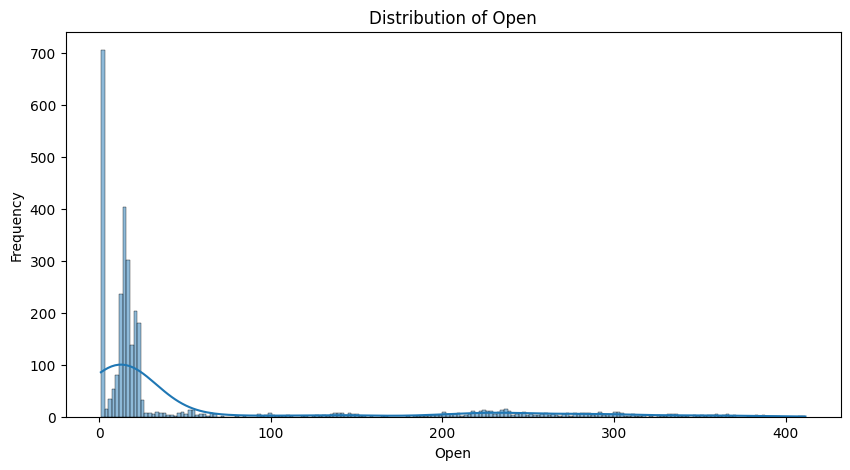

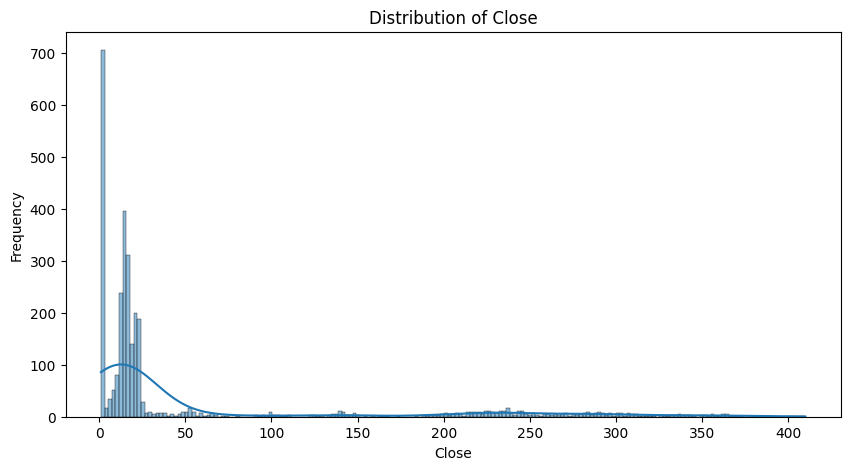

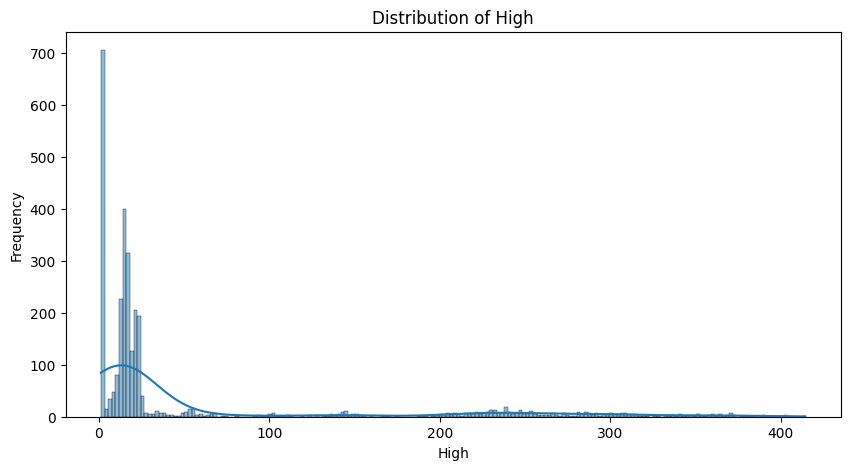

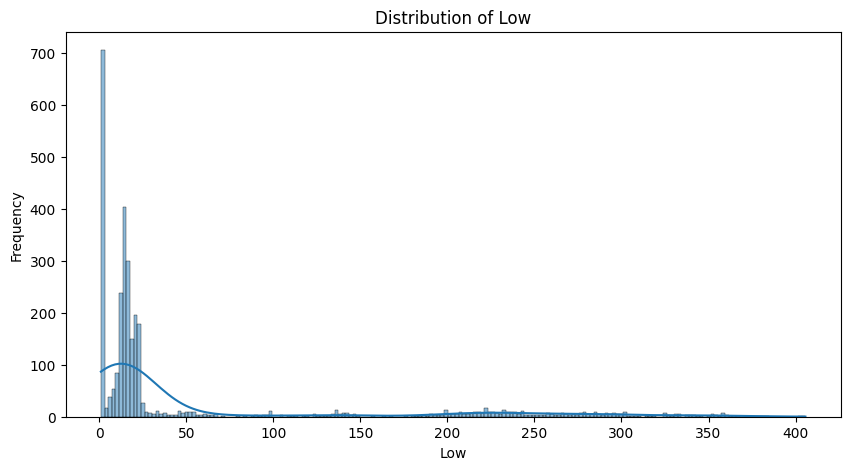

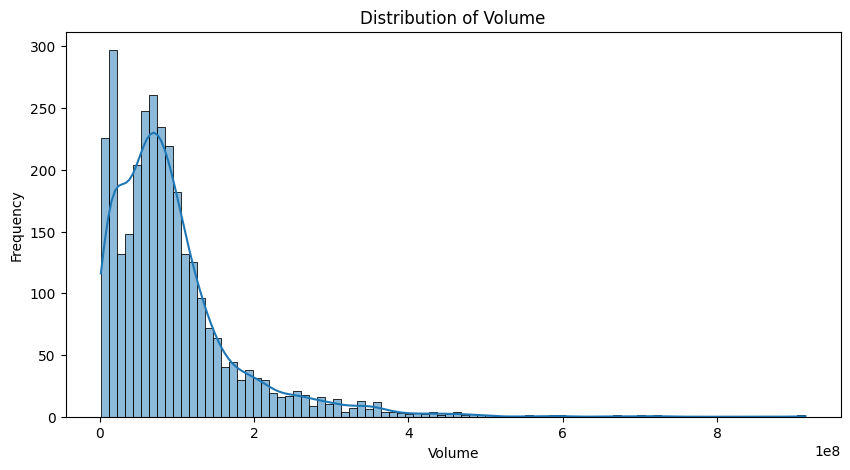

In [7]:
# ==============================
# 6. DISTRIBUTION ANALYSIS
# ==============================

columns = ["Open", "Close", "High", "Low", "Volume"]

for column in columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df[column],
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

In [8]:
# ==============================
# SKEWNESS ANALYSIS
# ==============================

skewness = df[columns].skew()

display(
    skewness.sort_values(
        ascending=False
    ).to_frame("Skewness")
)

,Skewness
Volume,2.377156
Open,1.985224
High,1.984721
Low,1.982624
Close,1.982340


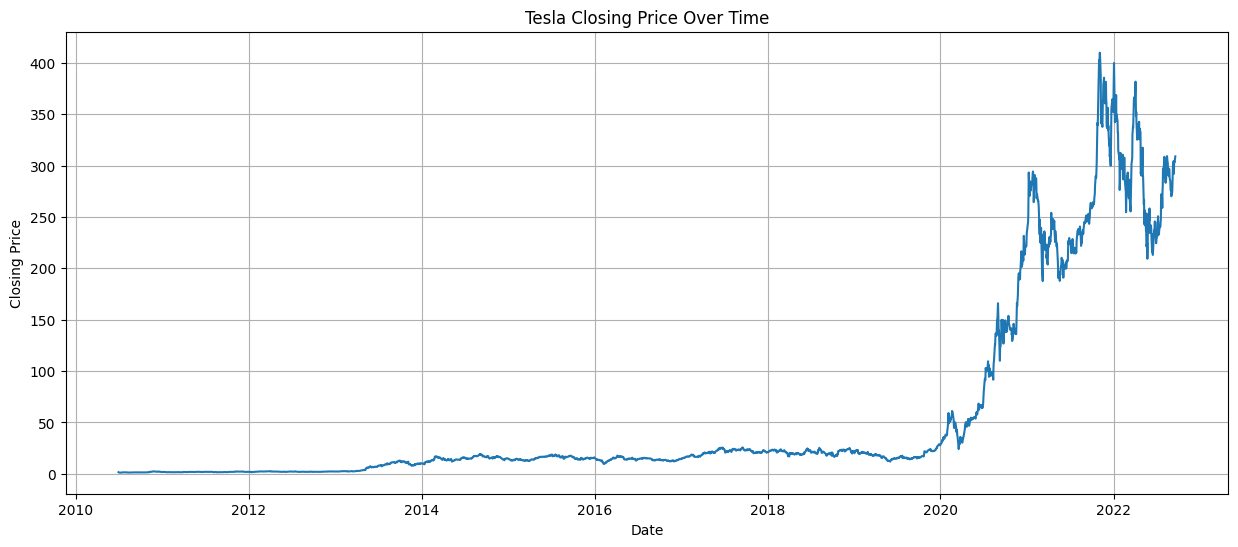

In [9]:
# ==============================
# 7. TIME TREND VISUALIZATION
# ==============================

plt.figure(figsize=(15, 6))

plt.plot(
    df["Date"],
    df["Close"]
)

plt.title("Tesla Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.grid(True)
plt.show()

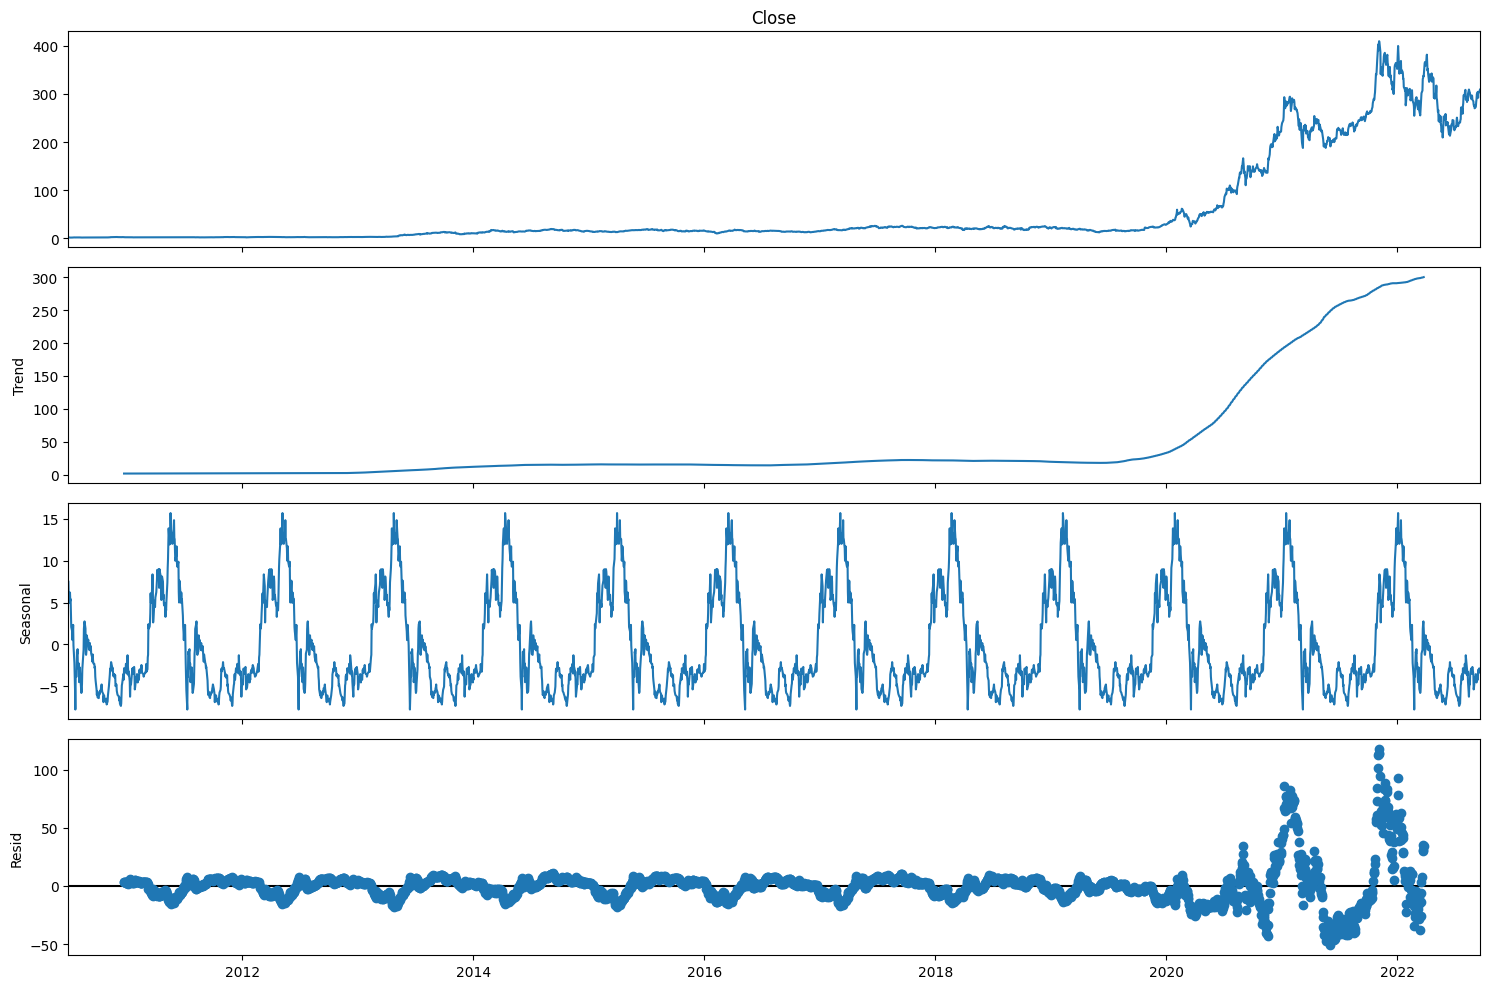

In [10]:
# ==============================
# 8. SEASONAL DECOMPOSITION
# ==============================

# Set Date as index
ts = df.set_index("Date")["Close"]

# Convert to business-day frequency
ts = ts.asfreq("B")

# Fill missing business days using interpolation
ts = ts.interpolate()

# Additive decomposition
decomposition = seasonal_decompose(
    ts,
    model="additive",
    period=252
)

fig = decomposition.plot()

fig.set_size_inches(15, 10)

plt.tight_layout()
plt.show()

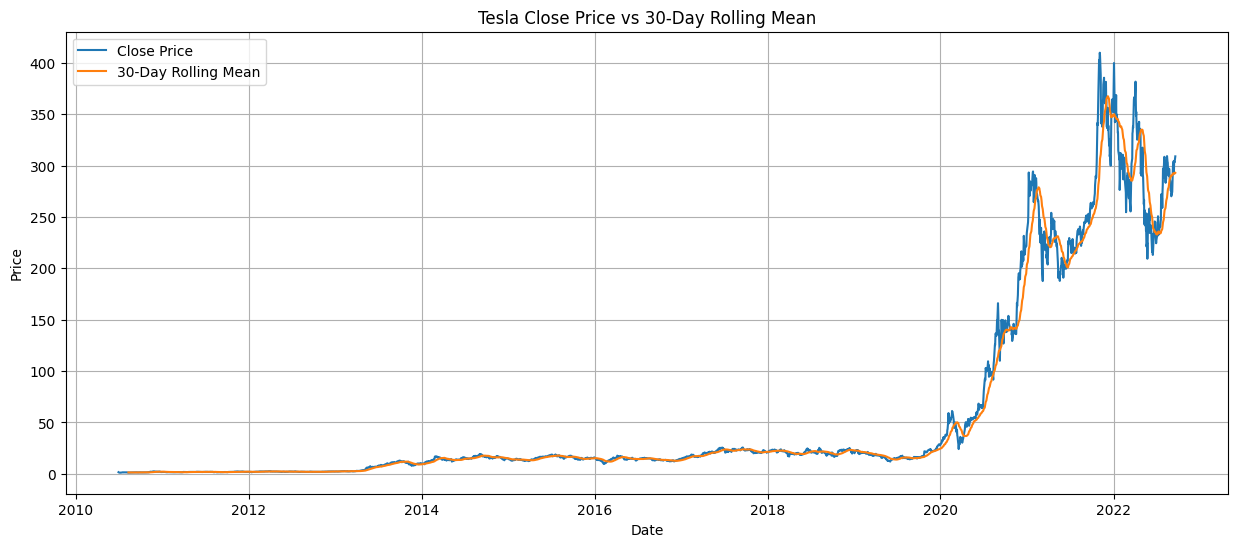

In [11]:
# ==============================
# 9. 30-DAY ROLLING MEAN
# ==============================

df["30_Day_Rolling_Mean"] = (
    df["Close"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="Close Price"
)

plt.plot(
    df["Date"],
    df["30_Day_Rolling_Mean"],
    label="30-Day Rolling Mean"
)

plt.title("Tesla Close Price vs 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)

plt.show()

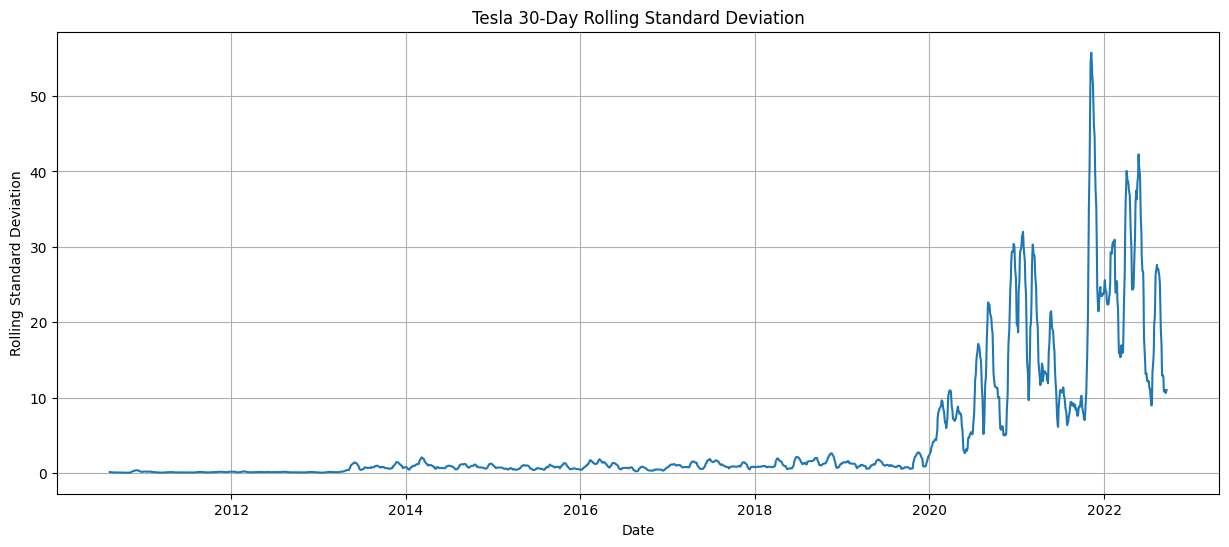

In [12]:
# ==============================
# 30-DAY ROLLING STANDARD DEVIATION
# ==============================

df["30_Day_Rolling_STD"] = (
    df["Close"]
    .rolling(window=30)
    .std()
)

plt.figure(figsize=(15, 6))

plt.plot(
    df["Date"],
    df["30_Day_Rolling_STD"]
)

plt.title("Tesla 30-Day Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Rolling Standard Deviation")

plt.grid(True)
plt.show()

In [13]:
# ==============================
# 10. CLUSTERING DATA
# ==============================

features = [
    "Close",
    "Price Change",
    "Price Range",
    "Pct Change",
    "Volatility",
    "Volume"
]

# Remove rows created as NaN by diff/rolling calculations
model_df = df.dropna(
    subset=features
).copy()

print("Rows available for clustering:", model_df.shape[0])

display(model_df[features].head())

Rows available for clustering: 3047


,Close,Price Change,Price Range,Pct Change,Volatility,Volume
30,1.173333,-0.020000,0.034000,-1.675978,5.809291,10365000
31,1.221333,0.048000,0.052667,4.090910,5.720752,9510000
32,1.252000,0.030667,0.036000,2.510945,5.262407,7287000
33,1.276667,0.024667,0.041333,1.970208,4.294352,6718500
34,1.251333,-0.025334,0.066000,-1.984386,4.295615,9019500


In [14]:
# ==============================
# 11. FEATURE SCALING
# ==============================

scaler = StandardScaler()

X = scaler.fit_transform(
    model_df[features]
)

scaled_df = pd.DataFrame(
    X,
    columns=features
)

display(
    scaled_df.describe().loc[
        ["mean", "std"]
    ]
)

,Close,Price Change,Price Range,Pct Change,Volatility,Volume
mean,-3.731107e-17,-4.663884e-18,-3.731107e-17,1.399165e-17,-3.731107e-16,-3.731107e-17
std,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00,1.000164e+00


In [15]:
# ==============================
# 12. FIND OPTIMAL K
# ==============================

silhouette_scores = {}

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        labels
    )

    silhouette_scores[k] = score

print("Silhouette Scores:")

for k, score in silhouette_scores.items():
    print(f"K = {k} : {score:.3f}")

Silhouette Scores:
K = 2 : 0.501
K = 3 : 0.470
K = 4 : 0.481
K = 5 : 0.467
K = 6 : 0.429
K = 7 : 0.255
K = 8 : 0.268


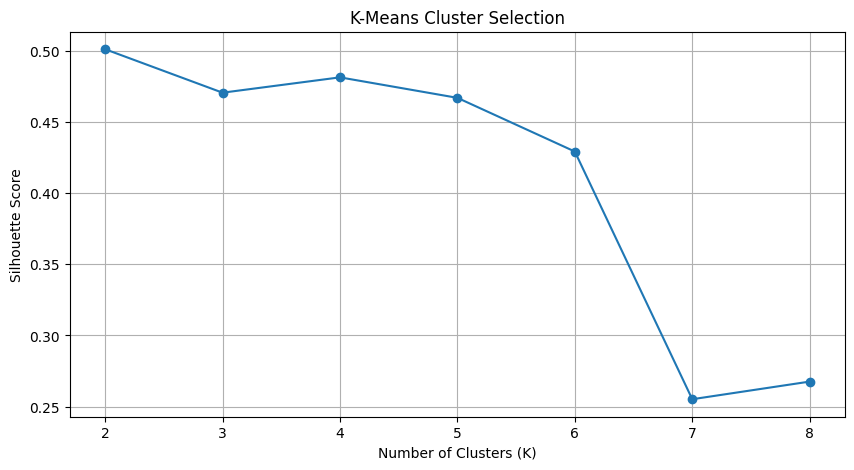

In [16]:
# Plot Silhouette Scores

plt.figure(figsize=(10, 5))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Cluster Selection")

plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

In [17]:
# Best K

best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print("Best K:", best_k)
print(
    "Best Silhouette Score:",
    round(silhouette_scores[best_k], 3)
)

Best K: 2
Best Silhouette Score: 0.501


In [18]:
# ==============================
# 13. K-MEANS CLUSTERING
# ==============================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

model_df["KMeans_Cluster"] = (
    kmeans.fit_predict(X)
)

kmeans_silhouette = silhouette_score(
    X,
    model_df["KMeans_Cluster"]
)

print(
    "K-Means Silhouette Score:",
    round(kmeans_silhouette, 3)
)

K-Means Silhouette Score: 0.501


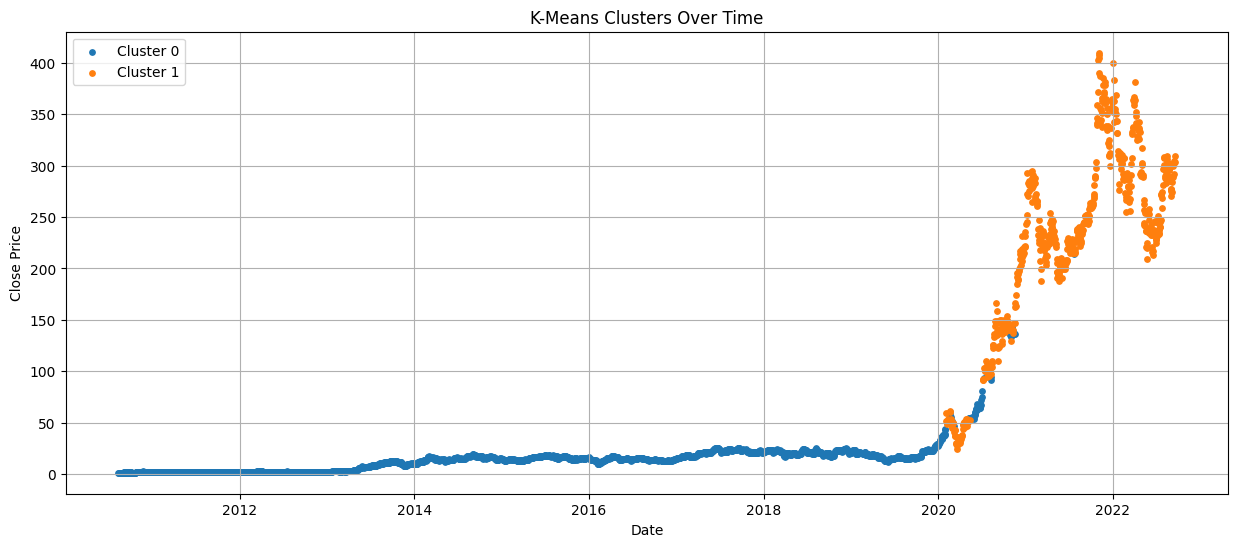

In [19]:
# ==============================
# K-MEANS VISUALIZATION
# ==============================

plt.figure(figsize=(15, 6))

for cluster in sorted(
    model_df["KMeans_Cluster"].unique()
):

    cluster_data = model_df[
        model_df["KMeans_Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["Date"],
        cluster_data["Close"],
        s=15,
        label=f"Cluster {cluster}"
    )

plt.title("K-Means Clusters Over Time")
plt.xlabel("Date")
plt.ylabel("Close Price")

plt.legend()
plt.grid(True)

plt.show()

In [20]:
# ==============================
# K-MEANS CLUSTER SUMMARY
# ==============================

kmeans_summary = (
    model_df
    .groupby("KMeans_Cluster")[features]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std"
        ]
    )
)

display(kmeans_summary)

Close                                    Price Change  \
               count        mean      median        std        count   
KMeans_Cluster                                                         
0               2454   14.389067   14.520667  14.372556         2454   
1                593  228.346232  236.603333  88.483640          593   

                                            Price Range             ...  \
                    mean    median      std       count       mean  ...   
KMeans_Cluster                                                      ...   
0               0.024403  0.005333  0.57722        2454   0.510745  ...   
1               0.418199  0.606674  9.64951         593  11.303363  ...   

               Pct Change           Volatility                                \
                   median       std      count      mean    median       std   
KMeans_Cluster                                                                 
0                0.090156  3.207176       2454  3.088422  2.912199  1.033310   
1                0.276714  4.710533        593  4.281284  4.110326  1.644103   

               Volume                                          
                count          mean      median           std  
KMeans_Cluster                                                 
0                2454  8.589611e+07  70527000.0  7.451479e+07  
1                 593  1.269460e+08  90296700.0  1.030284e+08  

[2 rows x 24 columns]

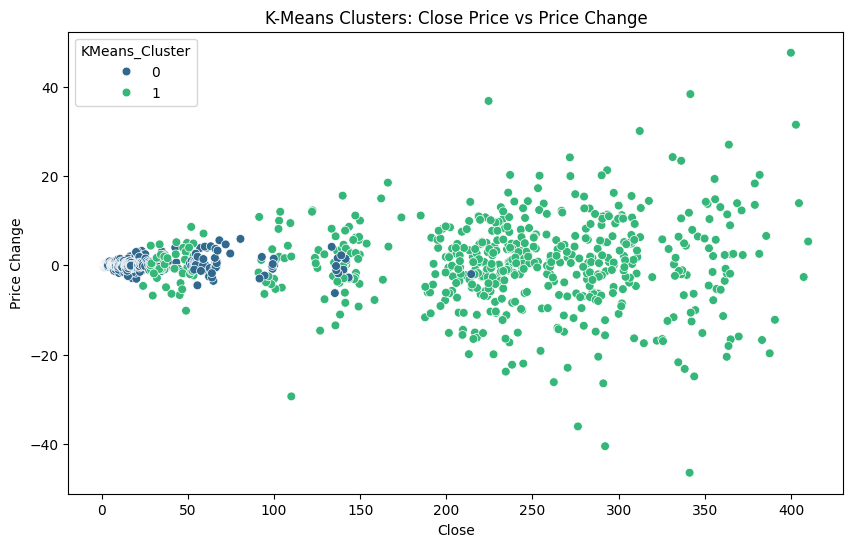

In [21]:
# ==============================
# CLOSE VS PRICE CHANGE
# ==============================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=model_df,
    x="Close",
    y="Price Change",
    hue="KMeans_Cluster",
    palette="viridis",
    s=40
)

plt.title(
    "K-Means Clusters: Close Price vs Price Change"
)

plt.show()

In [22]:
# ==============================
# 14. GAUSSIAN MIXTURE MODEL
# ==============================

gmm = GaussianMixture(
    n_components=best_k,
    random_state=42
)

model_df["GMM_Cluster"] = (
    gmm.fit_predict(X)
)

gmm_silhouette = silhouette_score(
    X,
    model_df["GMM_Cluster"]
)

print(
    "GMM Silhouette Score:",
    round(gmm_silhouette, 3)
)

GMM Silhouette Score: 0.465


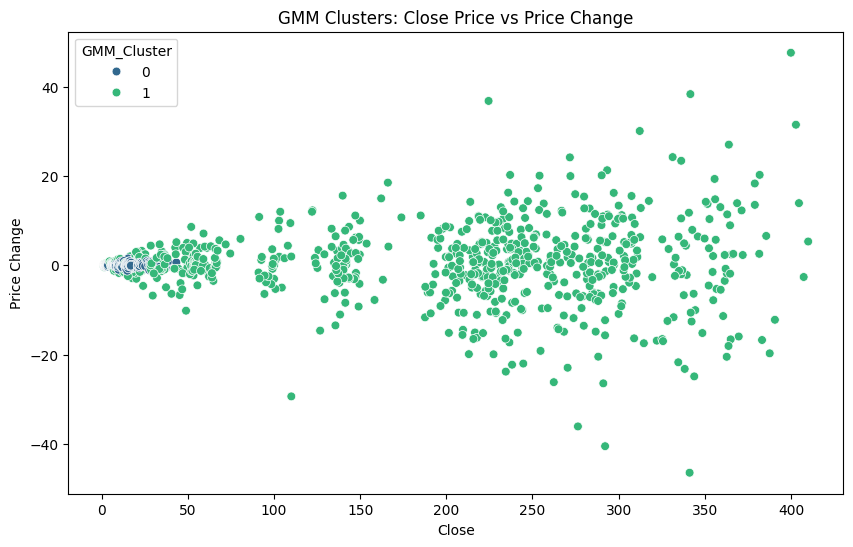

In [23]:
# ==============================
# GMM VISUALIZATION
# ==============================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=model_df,
    x="Close",
    y="Price Change",
    hue="GMM_Cluster",
    palette="viridis",
    s=40
)

plt.title(
    "GMM Clusters: Close Price vs Price Change"
)

plt.show()

In [24]:
# ==============================
# GMM MEMBERSHIP PROBABILITIES
# ==============================

gmm_probabilities = gmm.predict_proba(X)

probability_df = pd.DataFrame(
    gmm_probabilities,
    columns=[
        f"GMM_Probability_{i}"
        for i in range(best_k)
    ]
)

display(probability_df.head())

,GMM_Probability_0,GMM_Probability_1
0,1.000000,3.288446e-07
1,0.999999,1.331914e-06
2,1.000000,9.469937e-08
3,1.000000,1.124358e-08
4,1.000000,1.673316e-08


In [25]:
# ==============================
# 15. DBSCAN CLUSTERING
# ==============================

dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

model_df["DBSCAN_Cluster"] = (
    dbscan.fit_predict(X)
)

print(
    "Cluster Labels:",
    sorted(model_df["DBSCAN_Cluster"].unique())
)

print(
    "\nCluster Counts:"
)

print(
    model_df["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

Cluster Labels: [np.int64(-1), np.int64(0), np.int64(1)]

Cluster Counts:
DBSCAN_Cluster
-1      86
 0    2951
 1      10
Name: count, dtype: int64


In [26]:
# ==============================
# DBSCAN OUTLIER DETECTION
# ==============================

noise_count = (
    model_df["DBSCAN_Cluster"] == -1
).sum()

noise_percentage = (
    noise_count / len(model_df)
) * 100

print(
    "Number of Outliers:",
    noise_count
)

print(
    "Outlier Percentage:",
    round(noise_percentage, 2),
    "%"
)

Number of Outliers: 86
Outlier Percentage: 2.82 %


In [27]:
# ==============================
# DBSCAN SILHOUETTE SCORE
# ==============================

dbscan_mask = (
    model_df["DBSCAN_Cluster"] != -1
)

if (
    model_df.loc[
        dbscan_mask,
        "DBSCAN_Cluster"
    ].nunique() > 1
):

    dbscan_silhouette = silhouette_score(
        X[dbscan_mask],
        model_df.loc[
            dbscan_mask,
            "DBSCAN_Cluster"
        ]
    )

    print(
        "DBSCAN Silhouette Score:",
        round(dbscan_silhouette, 3)
    )

else:

    dbscan_silhouette = np.nan

    print(
        "Silhouette Score cannot be calculated."
    )

DBSCAN Silhouette Score: 0.576


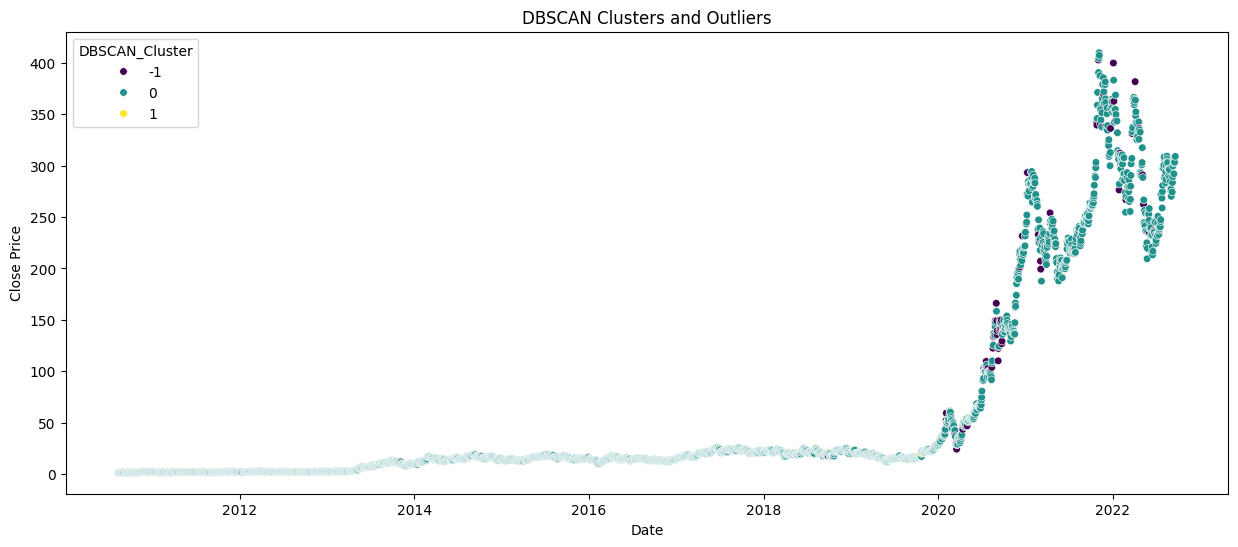

In [28]:
# ==============================
# DBSCAN VISUALIZATION
# ==============================

plt.figure(figsize=(15, 6))

sns.scatterplot(
    data=model_df,
    x="Date",
    y="Close",
    hue="DBSCAN_Cluster",
    palette="viridis",
    s=30
)

plt.title(
    "DBSCAN Clusters and Outliers"
)

plt.xlabel("Date")
plt.ylabel("Close Price")

plt.show()

In [29]:
# ==============================
# 16. ANOVA TEST
# ==============================

groups = []

for cluster in sorted(
    model_df["KMeans_Cluster"].unique()
):

    cluster_values = model_df[
        model_df["KMeans_Cluster"] == cluster
    ]["Close"]

    groups.append(cluster_values)

anova_result = f_oneway(*groups)

print(
    "F-statistic:",
    round(anova_result.statistic, 3)
)

print(
    "P-value:",
    anova_result.pvalue
)

F-statistic: 12947.665
P-value: 0.0


In [30]:
# ==============================
# ANOVA INTERPRETATION
# ==============================

alpha = 0.05

if anova_result.pvalue < alpha:

    print(
        "Reject H0: Mean Close price differs "
        "significantly between clusters."
    )

else:

    print(
        "Fail to reject H0: No significant "
        "difference detected between cluster means."
    )

Reject H0: Mean Close price differs significantly between clusters.


In [31]:
# ==============================
# 17. MODEL COMPARISON
# ==============================

comparison = pd.DataFrame({
    "Model": [
        "K-Means",
        "GMM",
        "DBSCAN"
    ],

    "Silhouette Score": [
        kmeans_silhouette,
        gmm_silhouette,
        dbscan_silhouette
    ]
})

display(comparison)

,Model,Silhouette Score
0,K-Means,0.500937
1,GMM,0.464837
2,DBSCAN,0.576043


In [32]:
# ==============================
# FINAL CLUSTER STATISTICS
# ==============================

final_summary = model_df.groupby(
    "KMeans_Cluster"
).agg(
    Total_Records=("Close", "count"),
    Avg_Close=("Close", "mean"),
    Median_Close=("Close", "median"),
    Avg_Price_Change=("Price Change", "mean"),
    Avg_Price_Range=("Price Range", "mean"),
    Avg_Pct_Change=("Pct Change", "mean"),
    Avg_Volatility=("Volatility", "mean"),
    Avg_Volume=("Volume", "mean")
)

display(final_summary)

,Total_Records,Avg_Close,Median_Close,Avg_Price_Change,Avg_Price_Range,Avg_Pct_Change,Avg_Volatility,Avg_Volume
KMeans_Cluster,,,,,,,,
0,2454,14.389067,14.520667,0.024403,0.510745,0.210517,3.088422,8.589611e+07
1,593,228.346232,236.603333,0.418199,11.303363,0.388083,4.281284,1.269460e+08


In [33]:
# ==============================
# FINAL RESULTS
# ==============================

print("=" * 50)
print("TESLA UNSUPERVISED LEARNING RESULTS")
print("=" * 50)

print(f"Dataset Shape       : {df.shape}")
print(f"Best K              : {best_k}")
print(f"K-Means Silhouette  : {kmeans_silhouette:.3f}")
print(f"GMM Silhouette      : {gmm_silhouette:.3f}")
print(f"DBSCAN Silhouette   : {dbscan_silhouette:.3f}")
print(f"DBSCAN Outliers     : {noise_count}")
print(f"Outlier Percentage  : {noise_percentage:.2f}%")
print(f"ANOVA F-statistic   : {anova_result.statistic:.3f}")
print(f"ANOVA P-value       : {anova_result.pvalue:.6f}")

print("=" * 50)

TESLA UNSUPERVISED LEARNING RESULTS
Dataset Shape       : (3077, 13)
Best K              : 2
K-Means Silhouette  : 0.501
GMM Silhouette      : 0.465
DBSCAN Silhouette   : 0.576
DBSCAN Outliers     : 86
Outlier Percentage  : 2.82%
ANOVA F-statistic   : 12947.665
ANOVA P-value       : 0.000000
